<a href="https://colab.research.google.com/github/xtianu/UPC_DAPR_2026/blob/main/S5/PCA_rotating_line_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **5. Principal Component Analysis (PCA)**

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **PART 2. PCA in 2 minutes: the rotating line**

**Idea:** PCA rotates the axes to look at the data from the best angle.
Here we rotate a line through a 2D cloud, project every point onto it, and watch the **variance of the projections** in real time.

> The angle where the variance is maximum is exactly the first eigenvector of the covariance matrix (PC1).

Run the cells in order. Cell 3 is the interactive one (use it live in class).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4.6), "font.size": 11})

# --- Data: correlated 2D Gaussian cloud (e.g. two process variables) ---
rng = np.random.default_rng(7)
C_true = np.array([[4.0, 1.8],
                   [1.8, 1.5]])
A = rng.multivariate_normal(mean=[0, 0], cov=C_true, size=300)
A = A - A.mean(axis=0)                 # STEP 1: center the data

# --- Variance of the projection onto a line at angle theta ---
def proj_variance(theta, A=A):
    u = np.array([np.cos(theta), np.sin(theta)])   # unit vector of the line
    p = A @ u                                      # scores: projection of each point
    return p.var(ddof=1)

thetas = np.linspace(0, np.pi, 361)
var_curve = np.array([proj_variance(t) for t in thetas])
print("Max variance found by rotating the line:", round(var_curve.max(), 3),
      "at angle", round(np.degrees(thetas[var_curve.argmax()]), 1), "deg")

Max variance found by rotating the line: 4.132 at angle 27.0 deg


## 1. Static view: variance as a function of the angle
Left: the data. Right: variance of the projection for every possible angle.

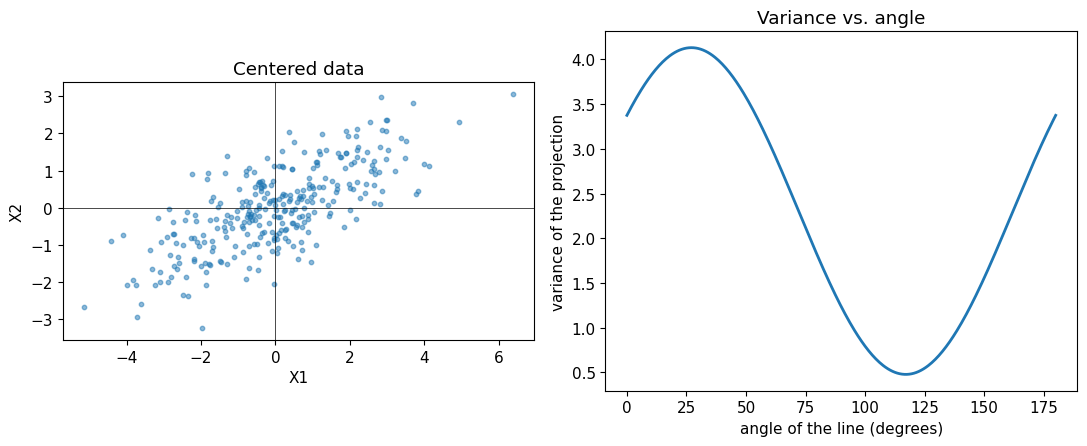

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.scatter(A[:, 0], A[:, 1], s=10, alpha=0.5)
ax1.set_aspect("equal"); ax1.axhline(0, c="k", lw=.5); ax1.axvline(0, c="k", lw=.5)
ax1.set_title("Centered data"); ax1.set_xlabel("X1"); ax1.set_ylabel("X2")

ax2.plot(np.degrees(thetas), var_curve, lw=2)
ax2.set_xlabel("angle of the line (degrees)")
ax2.set_ylabel("variance of the projection")
ax2.set_title("Variance vs. angle")
plt.tight_layout(); plt.show()

## 2. Interactive: rotate the line yourself
Move the slider. Watch the projections (red ticks) spread out or squeeze together, and the dot move along the variance curve.
Find the maximum with your students *before* revealing the eigenvector.

In [3]:
import ipywidgets as widgets
from IPython.display import display

def draw(angle_deg=0, show_pc1=False):
    theta = np.radians(angle_deg)
    u = np.array([np.cos(theta), np.sin(theta)])
    p = A @ u
    P = np.outer(p, u)                        # projected points (on the line)
    fig, (ax1, ax2) = plt.subplots(1, 2)

    # Left: cloud, line, projections
    ax1.scatter(A[:, 0], A[:, 1], s=10, alpha=0.35)
    L = 7
    ax1.plot([-L*u[0], L*u[0]], [-L*u[1], L*u[1]], c="crimson", lw=2)
    for a, q in zip(A[::6], P[::6]):          # thin lines to the projections
        ax1.plot([a[0], q[0]], [a[1], q[1]], c="gray", lw=.4, alpha=.6)
    ax1.scatter(P[:, 0], P[:, 1], s=8, c="crimson")
    if show_pc1:
        w, V = np.linalg.eigh(np.cov(A.T)); v1 = V[:, -1]
        ax1.plot([-L*v1[0], L*v1[0]], [-L*v1[1], L*v1[1]], "k--", lw=1.2, label="PC1 (eigenvector)")
        ax1.legend(loc="upper left")
    ax1.set_xlim(-7, 7); ax1.set_ylim(-7, 7); ax1.set_aspect("equal")
    ax1.set_title(f"Projection onto a line at {angle_deg:.0f} deg")

    # Right: variance curve with a moving dot
    ax2.plot(np.degrees(thetas), var_curve, lw=2)
    ax2.scatter([angle_deg % 180], [proj_variance(theta)], c="crimson", s=90, zorder=3)
    ax2.set_ylim(0, var_curve.max()*1.1)
    ax2.set_xlabel("angle (degrees)"); ax2.set_ylabel("variance of projection")
    ax2.set_title(f"Variance = {proj_variance(theta):.2f}")
    plt.tight_layout(); plt.show()

widgets.interact(draw,
                 angle_deg=widgets.FloatSlider(min=0, max=180, step=1, value=0, description="angle"),
                 show_pc1=widgets.Checkbox(value=False, description="reveal PC1"));

interactive(children=(FloatSlider(value=0.0, description='angle', max=180.0, step=1.0), Checkbox(value=False, …

## 3. The reveal: the maximum is the eigenvector
Now we do what PCA actually does: diagonalize the covariance matrix.

In [4]:
C = np.cov(A.T)                              # STEP 2: covariance matrix (1/(m-1) included)
eigvals, eigvecs = np.linalg.eigh(C)         # STEP 3: diagonalize
order = np.argsort(eigvals)[::-1]            # sort from largest to smallest
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

angle_pc1 = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0])) % 180
print("Covariance matrix:\n", np.round(C, 3))
print("\nEigenvalues:", np.round(eigvals, 3))
print("Eigenvector v1:", np.round(eigvecs[:, 0], 3), "-> angle", round(angle_pc1, 1), "deg")
print("\nMax variance by rotating the line :", round(var_curve.max(), 3))
print("Largest eigenvalue (lambda_1)      :", round(eigvals[0], 3))
print("Variance explained by PC1          :", round(100*eigvals[0]/eigvals.sum(), 1), "%")

Covariance matrix:
 [[3.375 1.48 ]
 [1.48  1.235]]

Eigenvalues: [4.132 0.479]
Eigenvector v1: [-0.89  -0.455] -> angle 27.1 deg

Max variance by rotating the line : 4.132
Largest eigenvalue (lambda_1)      : 4.132
Variance explained by PC1          : 89.6 %


## 4. Variance = information (and nothing is lost by magic)
The identity from the slides: **total variance = captured variance + reconstruction error**.
Maximizing the first term is the same as minimizing the second.

In [5]:
u = eigvecs[:, 0]
scores = A @ u                                   # STEP 4: project onto PC1
A_rec = np.outer(scores, u)                      # reconstruct from PC1 only
mean_sq_error = np.sum((A - A_rec)**2) / (len(A) - 1)

print("Total variance           :", round(np.trace(C), 3))
print("Captured variance (PC1)  :", round(scores.var(ddof=1), 3))
print("Reconstruction error     :", round(mean_sq_error, 3), " (= lambda_2 =", round(eigvals[1], 3), ")")
print("Captured + error         :", round(scores.var(ddof=1) + mean_sq_error, 3))

Total variance           : 4.61
Captured variance (PC1)  : 4.132
Reconstruction error     : 0.479  (= lambda_2 = 0.479 )
Captured + error         : 4.61


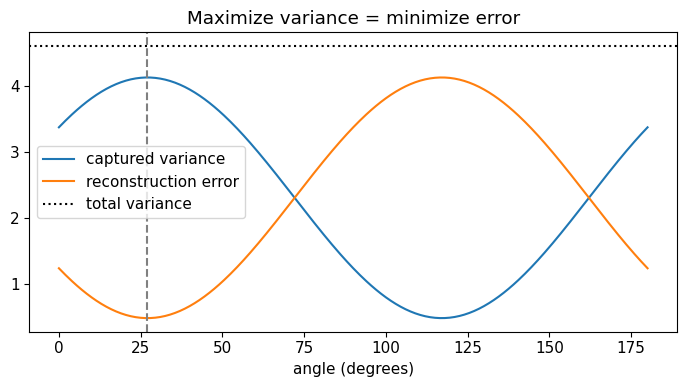

In [6]:
# Same identity for every angle: the line with max variance has min error
err_curve = np.trace(C) - var_curve
plt.figure(figsize=(7, 4))
plt.plot(np.degrees(thetas), var_curve, label="captured variance")
plt.plot(np.degrees(thetas), err_curve, label="reconstruction error")
plt.axhline(np.trace(C), c="k", ls=":", label="total variance")
plt.axvline(angle_pc1, c="gray", ls="--")
plt.xlabel("angle (degrees)"); plt.legend(); plt.title("Maximize variance = minimize error")
plt.tight_layout(); plt.show()

## Questions to ask the class
1. What happens to the variance curve if the two variables are **uncorrelated**? (Try `C_true = np.diag([4, 1.5])` and rerun.)
2. What if both variables have the **same variance** and are uncorrelated? (The curve becomes flat: every direction is equally good, PCA has nothing to find.)
3. Multiply X2 by 100 (change of units) and rerun. Does PC1 change? Why do we **standardize** before PCA?
4. The angle of PC1 is defined up to a sign (v and -v are equivalent). Why does it not matter?

---
# **Making a test**
*Hide or delete this section before sharing the notebook with students.* Each answer comes with a cell that proves it numerically.

General fact behind all four answers: the variance of the projection onto a unit vector **u** is

$$v(\theta) = \mathbf{u}^T C\,\mathbf{u}, \qquad \mathbf{u} = (\cos\theta, \sin\theta)$$

and its maximum over all directions is the largest eigenvalue of $C$, reached at the corresponding eigenvector.

In [8]:
# Helpers used by the answers below
def pca(X):
    """Eigenvalues (descending) and eigenvectors (columns) of the covariance matrix of X."""
    X = X - X.mean(axis=0)
    w, V = np.linalg.eigh(np.cov(X.T))
    idx = np.argsort(w)[::-1]
    return w[idx], V[:, idx]

def variance_curve(X):
    X = X - X.mean(axis=0)
    return np.array([(X @ np.array([np.cos(t), np.sin(t)])).var(ddof=1) for t in thetas])

def pc1_angle(V):
    """Angle of PC1 in degrees, in (-90, 90]."""
    a = np.degrees(np.arctan2(V[1, 0], V[0, 0])) % 180
    return a if a <= 90 else a - 180

def show(X, title):
    fig, (ax1, ax2) = plt.subplots(1, 2)
    ax1.scatter(X[:, 0], X[:, 1], s=8, alpha=0.5)
    ax1.set_aspect("equal"); ax1.axhline(0, c="k", lw=.5); ax1.axvline(0, c="k", lw=.5)
    ax1.set_title(title)
    ax2.plot(np.degrees(thetas), variance_curve(X), lw=2)
    ax2.set_xlabel("angle (degrees)"); ax2.set_ylabel("variance of projection"); ax2.set_ylim(0)
    ax2.set_title("Variance vs. angle")
    plt.tight_layout(); plt.show()

## **Answer 1. Uncorrelated variables**
With $C = \mathrm{diag}(\sigma_1^2, \sigma_2^2)$ the variance curve is simply

$$v(\theta) = \sigma_1^2\cos^2\theta + \sigma_2^2\sin^2\theta$$

It is maximum at $\theta = 0^\circ$ (the X1 axis) and minimum at $90^\circ$ (the X2 axis). The covariance matrix is already diagonal, so **the original axes are already the principal axes**: the eigenvalues are just the variances of X1 and X2, and PCA does not need to rotate anything. The cloud is an ellipse aligned with the axes.

Key message: PCA only "does something" when the variables are **correlated**. The off-diagonal term of $C$ is what tilts the ellipse.

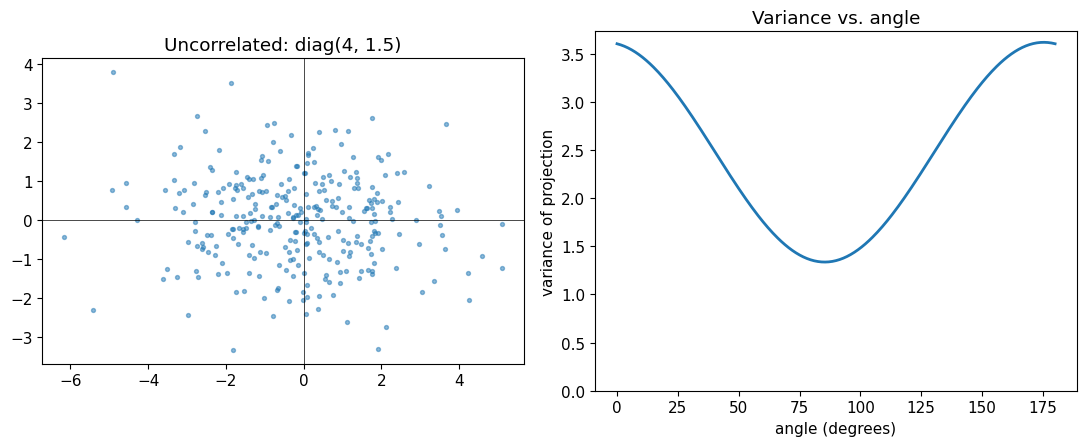

Variances of X1, X2 : [3.604 1.352]
Eigenvalues         : [3.62  1.337]  (almost the same numbers)
Angle of PC1        : -4.7 deg  (close to 0: the X1 axis)


In [9]:
rng = np.random.default_rng(1)
A_unc = rng.multivariate_normal([0, 0], np.diag([4.0, 1.5]), size=300)
show(A_unc, "Uncorrelated: diag(4, 1.5)")

w, V = pca(A_unc)
print("Variances of X1, X2 :", np.round(A_unc.var(axis=0, ddof=1), 3))
print("Eigenvalues         :", np.round(w, 3), " (almost the same numbers)")
print("Angle of PC1        :", round(pc1_angle(V), 1), "deg  (close to 0: the X1 axis)")

## **Answer 2. Same variance and uncorrelated**
Now $C = \sigma^2 I$ and

$$v(\theta) = \sigma^2(\cos^2\theta + \sin^2\theta) = \sigma^2 \quad \text{for every } \theta$$

The curve is **flat**: every direction captures the same variance. The cloud is a circle, the two eigenvalues are equal ($\lambda_1 = \lambda_2$), and the eigenvectors are not unique (any orthonormal pair works). Each PC explains 50% of the variance, so keeping only one component always loses half the information: **there is no low-dimensional structure to find**.

(With a finite sample the curve wiggles slightly. That is sampling noise and it shrinks as the number of points grows.)

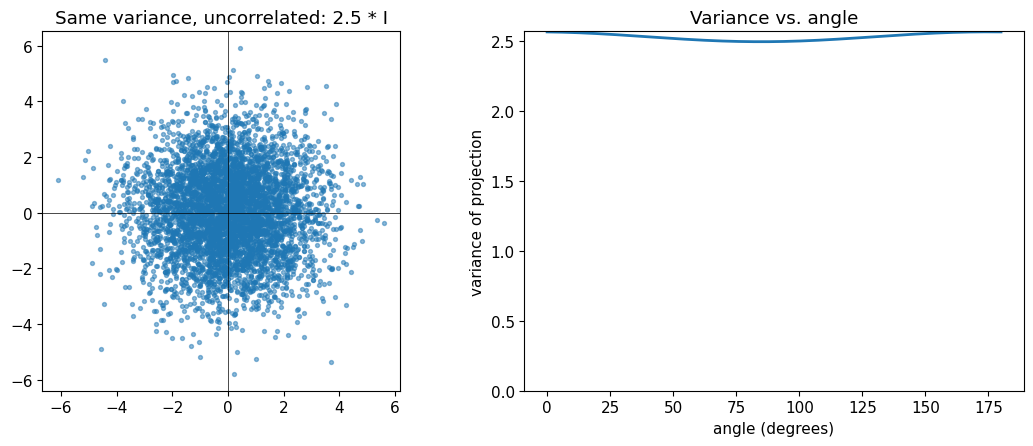

Eigenvalues         : [2.563 2.492]
Variance explained  : [50.7 49.3] %
Curve min / max     : 2.492 / 2.563 (nearly flat)


In [10]:
rng = np.random.default_rng(2)
A_iso = rng.multivariate_normal([0, 0], 2.5*np.eye(2), size=5000)
show(A_iso, "Same variance, uncorrelated: 2.5 * I")

w, V = pca(A_iso)
curve = variance_curve(A_iso)
print("Eigenvalues         :", np.round(w, 3))
print("Variance explained  :", np.round(100*w/w.sum(), 1), "%")
print("Curve min / max     :", round(curve.min(), 3), "/", round(curve.max(), 3), "(nearly flat)")

## **Answer 3. Change of units and why we standardize**
If X2 is multiplied by 100 (for example, a pressure expressed in different units), its variance grows by $100^2 = 10^4$. Since PCA hunts for maximum variance, **PC1 swings almost entirely onto the X2 axis** and explains essentially 100% of the variance. The structure of the data has not changed, only the unit of measurement, yet the result is completely different.

PCA on the covariance matrix is **not scale invariant**: variables with large numeric ranges dominate (temperature in hundreds vs. pH between 0 and 14). Standardizing each variable (zero mean, unit variance) puts all of them on equal footing. This is the same as running PCA on the **correlation matrix**, which is what Exercise 1 uses.

After standardizing, it makes no difference whether X2 was multiplied by 100 or not: the answer is identical. For two positively correlated variables, PC1 is then always at 45 degrees and the eigenvalues are $1 \pm \rho$.

In [ ]:
A_big = A.copy()
A_big[:, 1] *= 100                                   # change of units for X2

def zscore(X):
    return (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

cases = {
    "original data":               A,
    "X2 x 100 (no standardizing)": A_big,
    "X2 x 100, standardized":      zscore(A_big),
    "original, standardized":      zscore(A),
}
print(f"{'case':30s} {'PC1 angle':>10s} {'% explained by PC1':>20s}")
for name, X in cases.items():
    w, V = pca(X)
    print(f"{name:30s} {pc1_angle(V):9.1f}d {100*w[0]/w.sum():19.1f}%")

rho = np.corrcoef(A.T)[0, 1]
w, _ = pca(zscore(A))
print("\nCorrelation rho =", round(rho, 3), "-> eigenvalues should be 1+rho, 1-rho =",
      round(1+rho, 3), round(1-rho, 3), "| computed:", np.round(w, 3))

## **Answer 4. The sign of PC1 does not matter**
$\mathbf{v}$ and $-\mathbf{v}$ define **the same line**, and PCA only cares about the line (the subspace), not the direction in which we walk along it. If we flip the sign:

- the scores change sign ($p \to -p$), but $\mathrm{Var}(-p) = \mathrm{Var}(p)$, so the variance explained is identical;
- the reconstruction $p\,\mathbf{v} = (-p)(-\mathbf{v})$ is exactly the same;
- the eigenvalue equation $C\mathbf{v} = \lambda\mathbf{v}$ holds for both signs.

Practical consequences: the software chooses the sign arbitrarily (in this very notebook the eigenvector came out as $(-0.89, -0.46)$), so two runs or two programs may return opposite signs. Interpret the **relative** signs of the loadings within a component (which variables move together), never the absolute sign. If you need reproducible plots, fix a convention, for example "the largest loading is positive".

In [ ]:
w, V = pca(A)
v = V[:, 0]
results = {}
for sign in (+1, -1):
    vs = sign * v
    scores = A @ vs
    results[sign] = np.outer(scores, vs)             # reconstruction from PC1 only
    print(f"sign {sign:+d}: v = {np.round(vs, 3)} | variance of scores = {scores.var(ddof=1):.3f} "
          f"| first score = {scores[0]:+.3f}")

print("\nSame reconstruction with +v and -v?", np.allclose(results[+1], results[-1]))
print("C v = lambda v holds for -v too?    ", np.allclose(np.cov(A.T) @ (-v), w[0] * (-v)))